# GroupXX – Midterm: Ghép ảnh (image stitching) trên Colab – V0 (tuần tự, CPU)

**Thành viên:** <TODO: Tên – MSSV>, <TODO: Tên – MSSV>, …

**Dataset:** [Google Drive – Test-image](https://drive.google.com/drive/folders/1I1R7S_vAQuiHQvDeO4-8cR18JTbKruVz?usp=drive_link) (ảnh gốc của nhóm). Thư mục `dataset/` (cắt 16:9 + resize 3 cỡ) được sinh ở Phần A; cặp synthetic `data/A.ppm`, `data/B.ppm` được sinh bằng code ở ô 4.

**Cách dùng nhanh:** chạy lần lượt từ trên xuống. Cần GPU hay không đều được (V0 chạy trên CPU).

1. **Ô 1 – lấy code:** mặc định `SOURCE = "zip"`: upload file `GroupXX_Midterm.zip` khi được hỏi (giải nén ra `src/`). Đổi thành `"git"` nếu đã push `src/` mới lên repo.
2. **Ô 2–3:** kiểm tra stb (đã kèm sẵn trong `src/`) và biên dịch.
3. **Ô 4 – Dataset:** tải ảnh gốc `Test-image/` từ Google Drive và sinh cặp synthetic `data/A.ppm`, `data/B.ppm`.
4. **Phần A – Dữ liệu:** mỗi cặp ảnh được **cắt 16:9 rồi resize** về 3 cỡ: Small 1280×720, Medium 1920×1080, Large 3840×2160.
5. **Phần B – Correctness:** sai số homography trên cặp synthetic so với ground truth.
6. **Phần C – Chạy V0:** mọi cặp × 3 cỡ → bảng thời gian từng giai đoạn (lưu `results/timing_v0.csv`).
7. **Phần D – Panorama:** mỗi site một ảnh ghép.
8. **Phần E – Bảng timing** cho cả 3 độ phân giải.
9. **Phần F – Hot stages:** giai đoạn nào tốn nhất và thay đổi thế nào theo độ phân giải.
10. **Phần G – Ước lượng Amdahl:** báo cáo `p` và giới hạn `1/(1-p)` cho kế hoạch tăng tốc.

In [ ]:
# --- Lấy code -------------------------------------------------------------
# "zip": upload GroupXX_Midterm.zip (không cần push GitHub)
# "git": clone từ GitHub (cần đã push src/ mới lên repo; dataset lấy ở ô 4)
SOURCE = "zip"

import os, glob, zipfile, subprocess
if SOURCE == "zip":
    from google.colab import files
    name = next(iter(files.upload()))                       # chọn GroupXX_Midterm.zip
    zipfile.ZipFile(name).extractall(".")
    root = os.path.dirname(os.path.dirname(glob.glob("**/src/main.cpp", recursive=True)[0])) or "."
    os.chdir(root)
else:
    if not os.path.isdir("cloned-repo"):
        subprocess.run(["git", "clone", "-l", "-s", "https://github.com/DangDecTen/parallel-image-stitching.git", "cloned-repo"], check=True)
    os.chdir("cloned-repo")
print("Thư mục làm việc:", os.getcwd())
print(sorted(os.listdir(".")))

Saving GroupXX_Midterm (1).zip to GroupXX_Midterm (1).zip
Thư mục làm việc: /content
['.config', 'GroupXX_Midterm (1).zip', 'GroupXX_Midterm.ipynb', 'sample_data', 'src']


In [ ]:
%%bash
# stb_image.h / stb_image_write.h đã nằm sẵn trong src/ (có trong zip); chỉ tải nếu thiếu
cd src
[ -f stb_image.h ]       || wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
[ -f stb_image_write.h ] || wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h
ls

common.h
cuda_utils.cuh
io.h
main.cpp
stb_image.h
stb_image_write.h
stb_impl.cpp
v0_seq.cpp
versions.h


In [ ]:
%%bash
# Biên dịch V0 (CPU). stb_impl.cpp biên dịch phần cài đặt stb đúng một lần.
# Khi thêm phiên bản GPU: nvcc -O2 -std=c++17 src/main.cpp src/stb_impl.cpp src/v0_seq.cpp src/v1_<name>.cu -o stitch
g++ -O2 -std=c++17 src/main.cpp src/stb_impl.cpp src/v0_seq.cpp -o stitch
ls -la stitch

-rwxr-xr-x 1 root root 221448 Nov 12 04:43 stitch


In [ ]:
# --- Dataset của nhóm ------------------------------------------------------------
# (1) Ảnh gốc: thư mục Google Drive "Test-image" (chia sẻ "Anyone with the link") -> ./Test-image/ (tải hết)
DATASET_URL = "https://drive.google.com/drive/folders/1I1R7S_vAQuiHQvDeO4-8cR18JTbKruVz?usp=drive_link"

import os, glob, subprocess
import numpy as np
from PIL import Image, ImageDraw, ImageFilter

# Tải TOÀN BỘ file trong thư mục Drive (file nào đã có thì bỏ qua nhờ resume=True, nên chạy lại vẫn an toàn)
subprocess.run(["pip", "install", "-q", "-U", "gdown"], check=True)
import gdown
files = gdown.download_folder(DATASET_URL, output="Test-image", quiet=True, use_cookies=False, resume=True)
if not files:
    raise RuntimeError("Không tải được thư mục Drive - kiểm tra quyền chia sẻ 'Anyone with the link'.")

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".tif", ".tiff", ".webp")
imgs = sorted(p for p in glob.glob("Test-image/**/*", recursive=True) if p.lower().endswith(IMG_EXT))
print(f"Drive trả về {len(files)} file -> {len(imgs)} ảnh trong Test-image/:")
for p in imgs:
    print("  ", os.path.relpath(p, "Test-image"), f"({os.path.getsize(p)/1e6:.2f} MB)")
if len(files) >= 50:
    print("CẢNH BÁO: thư mục có >= 50 file; gdown có thể chỉ tải 50 file đầu -> chia nhỏ thư mục Drive nếu thiếu ảnh.")
if any(os.path.dirname(p) != "Test-image" for p in imgs):
    print("LƯU Ý: có ảnh nằm trong thư mục con; Phần A đọc ảnh ở mức Test-image/<tên>.jpg nên hãy đưa ảnh ra ngoài.")

# (2) Cặp synthetic cho Phần B (đúng thuật toán của make_synthetic_pair.py, seed cố định -> kết quả lặp lại được)
os.makedirs("data", exist_ok=True)
if not (os.path.exists("data/A.ppm") and os.path.exists("data/B.ppm")):
    rng = np.random.default_rng(1)
    W, H = 2100, 720
    base = np.zeros((H, W, 3), float)
    for s, a in [(4, 40), (16, 60), (64, 50)]:                 # nhiễu nhiều tầng
        n = rng.random((H // s + 2, W // s + 2, 3))
        im = Image.fromarray((n * 255).astype(np.uint8)).resize((W, H), Image.BICUBIC)
        base += a * (np.asarray(im) / 255.0 - 0.5) * 2
    base += 128
    img = Image.fromarray(np.clip(base, 0, 255).astype(np.uint8))
    d = ImageDraw.Draw(img)
    for i in range(120):                                       # hình chữ nhật ngẫu nhiên
        x, y = rng.integers(0, W), rng.integers(0, H); w, h = rng.integers(10, 60, 2)
        d.rectangle([x, y, x + w, y + h], fill=tuple(int(v) for v in rng.integers(0, 255, 3)))
    img = img.filter(ImageFilter.GaussianBlur(0.8))
    A = img.crop((0, 0, 1280, 720))
    c = (1.0, 0.03, 700.0, -0.03, 1.0, 5.0, 2e-5, 0.0)         # H thật: pixel của B -> toạ độ của A
    B = img.transform((1280, 720), Image.PERSPECTIVE, c, Image.BICUBIC)
    A.save("data/A.ppm"); B.save("data/B.ppm")
print("data:", sorted(os.listdir("data")))

Drive trả về 18 file -> 18 ảnh trong Test-image/:
   2026-11-07-17-55-23-759.jpg (3.86 MB)
   2026-11-07-17-55-37-434.jpg (4.09 MB)
   indoor1_1.jpg (3.14 MB)
   indoor1_2.jpg (3.18 MB)
   indoor1_3.jpg (3.87 MB)
   indoor1_4.jpg (3.47 MB)
   outdoor1_1.jpg (3.95 MB)
   outdoor1_2.jpg (4.26 MB)
   outdoor1_3.jpg (3.98 MB)
   outdoor1_4.jpg (4.37 MB)
   outdoor2_1.jpg (2.83 MB)
   outdoor2_2.jpg (2.40 MB)
   outdoor3_1.jpg (3.71 MB)
   outdoor3_2.jpg (3.77 MB)
   outdoor4_1.jpg (6.96 MB)
   outdoor4_2.jpg (7.96 MB)
   outdoor5_1.jpg (8.59 MB)
   outdoor5_2.jpg (6.34 MB)
data: ['A.ppm', 'B.ppm']


## Phần A – Chuẩn bị dữ liệu: cắt 16:9 và resize 3 cỡ

Theo yêu cầu: mỗi nhóm có **≥ 3 site** (vd. 1 trong nhà, 1 ngoài trời, 1 tùy chọn), mỗi site **1 cặp standard**, cộng **1 cặp challenging** (ít texture, hoa văn lặp, người di chuyển, ban đêm…).
Mỗi cặp được cắt về tỉ lệ 16:9 (cắt giữa, cùng một phép cắt cho cả ảnh trái và phải) rồi resize về 3 cỡ để so sánh speedup trên **đúng cùng một cảnh**.

Lưu ý khi chụp: **xoay máy, không đi ngang** (parallax mà homography không sửa được) và **overlap 30–50%** giữa hai ảnh.

👉 Sửa danh sách `PAIRS` cho đúng ảnh của nhóm (ảnh đầu = ảnh TRÁI/tham chiếu, ảnh sau = ảnh PHẢI).

In [ ]:
import os
from PIL import Image, ImageOps

# Ba cỡ theo đề bài:  small = phát triển/debug,  medium = benchmark chính,  large = xem GPU scaling
SIZES = {"small": (1280, 720), "medium": (1920, 1080), "large": (3840, 2160)}

# (site, loại cặp, ảnh TRÁI, ảnh PHẢI)  -- SỬA cho đúng dữ liệu của nhóm
PAIRS = [
    ("indoor1",  "standard",    "Test-image/indoor1_2.jpg",  "Test-image/indoor1_3.jpg"),
    ("outdoor1", "standard",    "Test-image/outdoor1_2.jpg", "Test-image/outdoor1_3.jpg"),
    ("outdoor2", "standard",    "Test-image/outdoor2_1.jpg", "Test-image/outdoor2_2.jpg"),
    ("outdoor3", "challenging", "Test-image/outdoor3_1.jpg", "Test-image/outdoor3_2.jpg"),   # cảnh ban đêm, có xe chạy
]

def crop_16x9(im):
    """Cắt chính giữa về tỉ lệ 16:9 (ảnh 4:3 bị cắt bớt phần trên/dưới)."""
    w, h = im.size
    new_h = round(w * 9 / 16)
    if new_h <= h:
        top = (h - new_h) // 2
        return im.crop((0, top, w, top + new_h))
    new_w = round(h * 16 / 9)
    left = (w - new_w) // 2
    return im.crop((left, 0, left + new_w, h))

def make_sizes(path, site, side):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")   # xử lý ảnh chụp dọc (EXIF)
    im = crop_16x9(im)
    for name, (W, H) in SIZES.items():
        os.makedirs(f"dataset/{name}", exist_ok=True)
        im.resize((W, H), Image.LANCZOS).save(f"dataset/{name}/{site}_{side}.png", compress_level=1)   # <-- RESIZE ảnh về cỡ small/medium/large
    return im.size

for site, kind, left, right in PAIRS:
    for side, path in (("L", left), ("R", right)):
        assert os.path.exists(path), f"Không thấy ảnh: {path}"
        cw, ch = make_sizes(path, site, side)
    print(f"{site:10s} [{kind:11s}] cắt 16:9 -> {cw}x{ch}  ->  " + ", ".join(f"{n} {w}x{h}" for n, (w, h) in SIZES.items()))
print(sorted(os.listdir("dataset")))

indoor1    [standard   ] cắt 16:9 -> 4656x2619  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor1   [standard   ] cắt 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor2   [standard   ] cắt 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
outdoor3   [challenging] cắt 16:9 -> 4032x2268  ->  small 1280x720, medium 1920x1080, large 3840x2160
['large', 'medium', 'small']


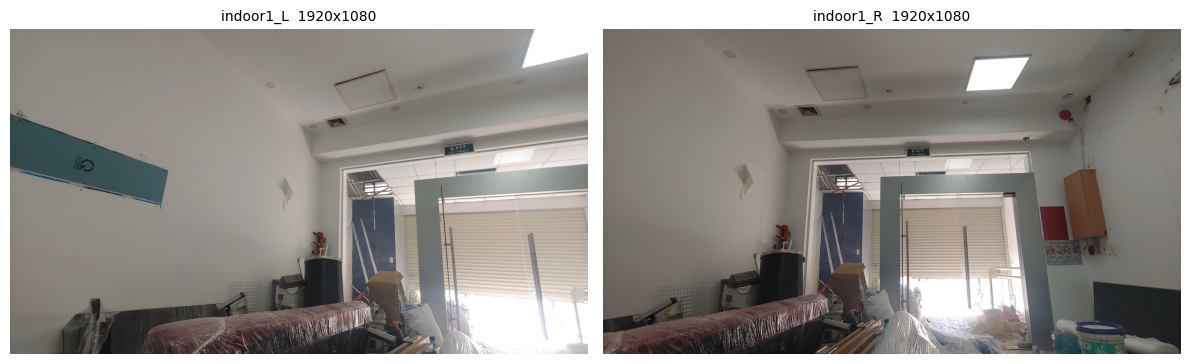

In [ ]:
# Xem nhanh một cặp ở cỡ medium
import matplotlib.pyplot as plt
site = PAIRS[0][0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, side in zip(axes, "LR"):
    im = Image.open(f"dataset/medium/{site}_{side}.png")
    ax.imshow(im); ax.set_title(f"{site}_{side}  {im.size[0]}x{im.size[1]}", fontsize=10); ax.axis("off")
plt.tight_layout()

## Phần B – Correctness: sai số homography trên cặp synthetic

`data/A.ppm` và `data/B.ppm` được sinh ở ô 4 (thuật toán của `make_synthetic_pair.py`) với homography thật (ground truth) ánh xạ **pixel của B → toạ độ của A**.
Chạy V0 với `--focal 0` (phép chiếu phẳng, không tìm tiêu cự) để `H` ước lượng so sánh trực tiếp được với ground truth.
Sai số = khoảng cách (pixel) giữa hai phép biến đổi trên lưới 5×5 điểm của ảnh B.

In [ ]:
import re, subprocess
import numpy as np

H_TRUE = np.array([[1.0,   0.03, 700.0],
                   [-0.03, 1.0,    5.0],
                   [2e-5,  0.0,    1.0]])          # = tham số c trong data/make_synthetic_pair.py

r = subprocess.run(["./stitch", "data/A.ppm", "data/B.ppm", "pano_synthetic.png",
                    "--version", "0", "--runs", "1", "--focal", "0"], capture_output=True, text=True)
print(r.stdout.split("stage times")[0])

m = re.search(r"H = \[(.*?)\]", r.stdout)
H_EST = np.array([float(x) for x in m.group(1).replace(";", " ").split()]).reshape(3, 3)
H_EST /= H_EST[2, 2]

def warp_pts(H, pts):
    q = np.c_[pts, np.ones(len(pts))] @ H.T
    return q[:, :2] / q[:, 2:3]

W, Hh = 1280, 720
gx, gy = np.meshgrid(np.linspace(0, W - 1, 5), np.linspace(0, Hh - 1, 5))
pts = np.c_[gx.ravel(), gy.ravel()]
err = np.linalg.norm(warp_pts(H_EST, pts) - warp_pts(H_TRUE, pts), axis=1)

print("H thật     :", np.round(H_TRUE.ravel(), 6))
print("H ước lượng:", np.round(H_EST.ravel(), 6))
print(f"Sai số homography (lưới 5x5 điểm của B): trung bình = {err.mean():.3f} px | lớn nhất = {err.max():.3f} px")

version=0  input=1280x720  runs=1  device=CPU(single thread)
keypoints A/B: 208/263  matches: 72  inliers: 70  stitched: yes
H = [ 1.00196  0.03137  699.69619; -0.02989  1.00137  4.78178;  0.000021  0.000001  1.000000]
projection: planar

H thật     : [ 1.e+00  3.e-02  7.e+02 -3.e-02  1.e+00  5.e+00  2.e-05  0.e+00  1.e+00]
H ước lượng: [ 1.0019600e+00  3.1370000e-02  6.9969619e+02 -2.9890000e-02
  1.0013700e+00  4.7817800e+00  2.1000000e-05  1.0000000e-06
  1.0000000e+00]
Sai số homography (lưới 5x5 điểm của B): trung bình = 0.242 px | lớn nhất = 0.806 px


## Phần C – Chạy V0 trên mọi cặp × 3 cỡ

Mỗi lần chạy `./stitch` có 1 lượt warm-up (không tính) rồi `RUNS` lượt đo; số liệu là **trung bình** từng giai đoạn (ms). Panorama được lưu vào `results/pano_v0_<site>_<cỡ>.png`, bảng số liệu vào `results/timing_v0.csv`.
`large` chạy tuần tự có thể mất vài giây/lượt nên mặc định dùng ít `RUNS` hơn.

In [ ]:
import time
import pandas as pd

VERSION = 0
RUNS    = {"small": 5, "medium": 5, "large": 3}
FOCAL   = None        # None = tự tìm tiêu cự (như mặc định); 0 = phép chiếu phẳng; số dương = cố định
STAGES  = ["proj", "gray", "blur", "fast", "brief", "match", "ransac", "warp", "h2d", "d2h"]   # thứ tự các giai đoạn trong báo cáo

os.makedirs("results", exist_ok=True)

def parse_output(out):
    """Đọc stdout của ./stitch: số điểm đặc trưng, H, thời gian trung bình từng giai đoạn."""
    d = {}
    m = re.search(r"keypoints A/B: (\d+)/(\d+)\s+matches: (\d+)\s+inliers: (\d+)", out)
    if m: d.update(kpA=int(m[1]), kpB=int(m[2]), matches=int(m[3]), inliers=int(m[4]))
    m = re.search(r"projection: (\w+)", out);          d["projection"] = m[1] if m else ""
    m = re.search(r"panorama (\d+)x(\d+)", out)
    d["pano_w"], d["pano_h"] = (int(m[1]), int(m[2])) if m else (0, 0)
    for line in out.splitlines():                        # "  warp   245.724 |   245.724"
        m = re.match(r"\s+(\S+)\s+([\d.]+)\s*\|\s*([\d.]+)\s*$", line)
        if m: d[m[1]] = float(m[2])
    return d

def run_pair(site, kind, size):
    L, R = f"dataset/{size}/{site}_L.png", f"dataset/{size}/{site}_R.png"
    out = f"results/pano_v{VERSION}_{site}_{size}.png"
    cmd = ["./stitch", L, R, out, "--version", str(VERSION), "--runs", str(RUNS[size])]
    if FOCAL is not None: cmd += ["--focal", str(FOCAL)]
    t0 = time.time()
    r = subprocess.run(cmd, capture_output=True, text=True)
    row = dict(site=site, kind=kind, size=size, W=SIZES[size][0], H=SIZES[size][1],
               ok=(r.returncode == 0), wall_s=round(time.time() - t0, 1))
    row.update(parse_output(r.stdout))
    if r.returncode == 1: print(r.stderr)               # lỗi đọc/ghi file
    return row

rows = []
for site, kind, _, _ in PAIRS:
    for size in SIZES:
        row = run_pair(site, kind, size); rows.append(row)
        print(f"{site:9s} {size:6s} {row['W']}x{row['H']}  {'OK ' if row['ok'] else 'FAIL'}  inliers={row.get('inliers','-'):>5}  "
              f"total={row.get('total(e2e)', float('nan')):9.1f} ms  ({row['wall_s']} s)")

df = pd.DataFrame(rows)
df.to_csv(f"results/timing_v{VERSION}.csv", index=False)

indoor1   small  1280x720  OK   inliers=   73  total=    971.1 ms  (6.2 s)
indoor1   medium 1920x1080  OK   inliers=   76  total=   1151.5 ms  (7.3 s)
indoor1   large  3840x2160  OK   inliers=  106  total=   4241.5 ms  (19.9 s)
outdoor1  small  1280x720  OK   inliers=  502  total=   1281.2 ms  (7.9 s)
outdoor1  medium 1920x1080  OK   inliers=  890  total=   4256.0 ms  (26.1 s)
outdoor1  large  3840x2160  OK   inliers=  401  total=  11180.3 ms  (47.7 s)
outdoor2  small  1280x720  OK   inliers=  275  total=   1366.4 ms  (8.7 s)
outdoor2  medium 1920x1080  OK   inliers=  318  total=   1961.7 ms  (12.5 s)
outdoor2  large  3840x2160  OK   inliers=  158  total=   7610.7 ms  (33.4 s)
outdoor3  small  1280x720  OK   inliers=  603  total=   1107.5 ms  (6.9 s)
outdoor3  medium 1920x1080  OK   inliers=  709  total=   2375.8 ms  (15.2 s)
outdoor3  large  3840x2160  OK   inliers=  261  total=  10131.9 ms  (45.5 s)


## Phần D – Panorama: mỗi site một ảnh

Ảnh ghép của các cặp **standard** (một ảnh/site) và cặp **challenging** ở cỡ medium. Các cỡ khác nằm trong `results/`.

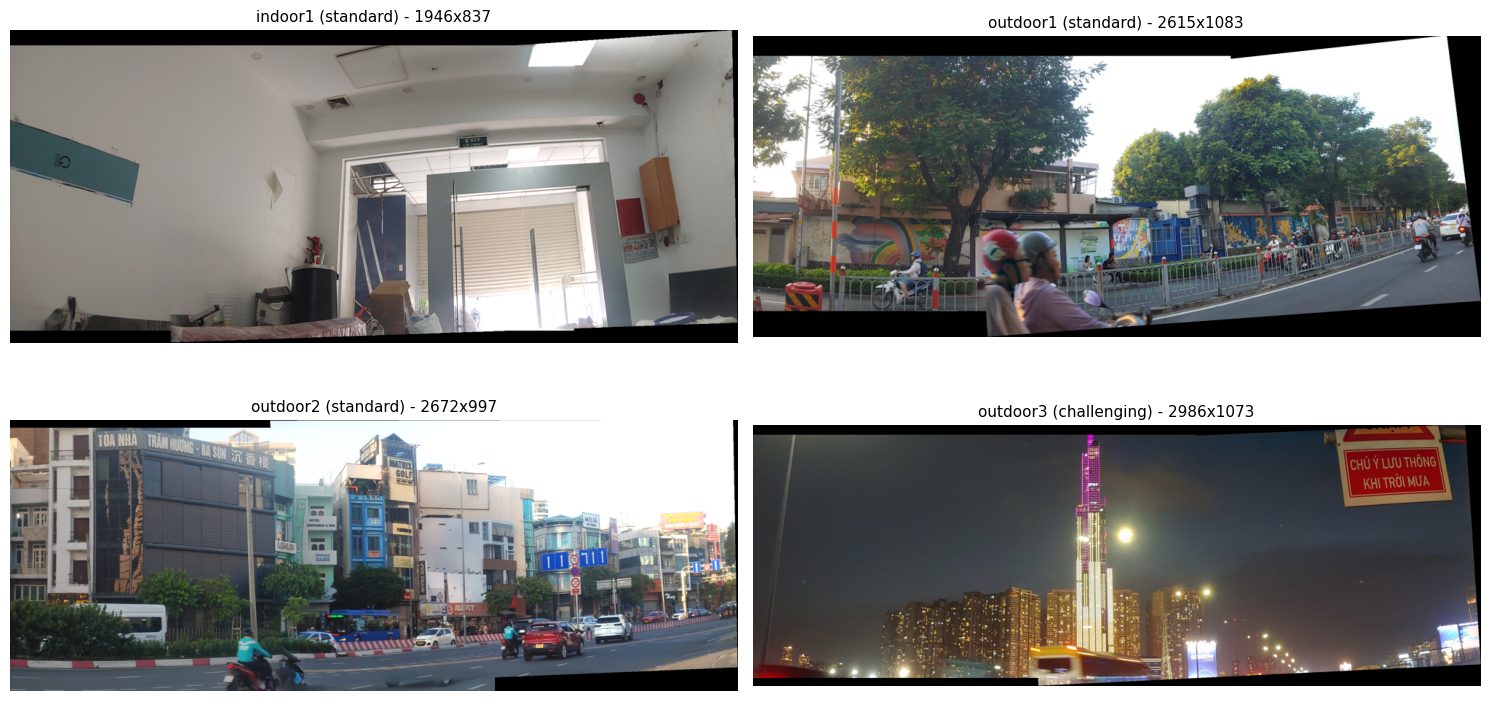

In [ ]:
SHOW_SIZE = "medium"
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (site, kind, _, _) in zip(axes.ravel(), PAIRS):
    p = f"results/pano_v{VERSION}_{site}_{SHOW_SIZE}.png"
    ax.axis("off")
    if os.path.exists(p):
        im = Image.open(p); w, h = im.size; im.thumbnail((1000, 700))
        ax.imshow(im); ax.set_title(f"{site} ({kind}) - {w}x{h}", fontsize=11)
    else:
        ax.set_title(f"{site} ({kind}) - GHÉP THẤT BẠI (không đủ điểm khớp)", fontsize=11, color="red")
plt.tight_layout()

## Phần E – Bảng timing từng giai đoạn (small / medium / large)

Trung bình trên các cặp **standard** (cặp challenging bị loại khỏi trung bình vì có thể thất bại hoặc lệch số điểm đặc trưng). `other` = `total(e2e)` trừ tổng các giai đoạn (chi phí không thuộc giai đoạn nào).

In [ ]:
std = df[(df.kind == "standard") & df.ok]
cols = ["proj", "gray", "blur", "fast", "brief", "match", "ransac", "warp", "h2d", "d2h", "total(e2e)"]
tab = std.groupby("size")[cols].mean().reindex(list(SIZES)).T
tab.loc["other"] = tab.loc["total(e2e)"] - tab.loc[STAGES].sum()
tab = tab.loc[STAGES + ["other", "total(e2e)"]]
tab.columns = [f"{s} ({SIZES[s][0]}x{SIZES[s][1]})" for s in tab.columns]
print(f"Thời gian V0 (ms), trung bình {std.site.nunique()} cặp standard\n")
display(tab.round(2))

# số liệu từng cặp (để đối chiếu / đưa vào phụ lục)
display(df[["site", "kind", "size", "ok", "kpA", "kpB", "matches", "inliers", "projection", "pano_w", "pano_h", "total(e2e)"]].round(1))

Thời gian V0 (ms), trung bình 3 cặp standard



,small (1280x720),medium (1920x1080),large (3840x2160)
proj,203.40,360.99,1947.81
gray,4.20,7.51,34.24
blur,47.73,74.85,322.43
fast,82.98,142.51,584.51
brief,17.59,28.68,44.21
match,248.95,1012.96,1564.71
ransac,7.56,9.57,7.21
warp,593.84,819.34,3170.34
h2d,0.00,0.00,0.00
d2h,0.00,0.00,0.00


,site,kind,size,ok,kpA,kpB,matches,inliers,projection,pano_w,pano_h,total(e2e)
0,indoor1,standard,small,True,263,306,103,73,cylindrical,1338,574,971.1
1,indoor1,standard,medium,True,402,574,133,76,cylindrical,1946,837,1151.5
2,indoor1,standard,large,True,866,1289,232,106,cylindrical,3908,1679,4241.5
3,outdoor1,standard,small,True,3205,2443,540,502,cylindrical,1731,720,1281.2
4,outdoor1,standard,medium,True,7397,5932,1053,890,cylindrical,2615,1083,4256.0
5,outdoor1,standard,large,True,8000,8000,661,401,cylindrical,5184,2165,11180.3
6,outdoor2,standard,small,True,2067,1935,323,275,planar,2371,1037,1366.4
7,outdoor2,standard,medium,True,2860,2746,404,318,cylindrical,2672,997,1961.7
8,outdoor2,standard,large,True,5063,4907,412,158,cylindrical,5246,2016,7610.7
9,outdoor3,challenging,small,True,2119,1863,624,603,cylindrical,1995,718,1107.5


## Phần F – Hot stages

Giai đoạn nào chiếm nhiều thời gian nhất và tỉ trọng thay đổi thế nào khi tăng độ phân giải. Số pixel: medium gấp **2.25×** small, large gấp **9×** small – giai đoạn nào tăng gần 9× là tỉ lệ thuận với số pixel; tăng chậm hơn nhiều thường là phần phụ thuộc số điểm đặc trưng/số match (bị giới hạn bởi `TOPK`) chứ không phụ thuộc số pixel.

Tỉ trọng mỗi giai đoạn trong tổng thời gian (%):


,small,medium,large
proj,16.9,14.7,25.4
gray,0.3,0.3,0.4
blur,4.0,3.0,4.2
fast,6.9,5.8,7.6
brief,1.5,1.2,0.6
match,20.6,41.2,20.4
ransac,0.6,0.4,0.1
warp,49.2,33.4,41.3
h2d,0.0,0.0,0.0
d2h,0.0,0.0,0.0


Hệ số tăng thời gian so với small:


,small,medium,large
proj,1.0,1.77,9.58
gray,1.0,1.79,8.15
blur,1.0,1.57,6.76
fast,1.0,1.72,7.04
brief,1.0,1.63,2.51
match,1.0,4.07,6.29
ransac,1.0,1.27,0.95
warp,1.0,1.38,5.34
total(e2e),1.0,2.04,6.36
(số pixel),1.0,2.25,9.00


small  - hot stages: warp 49.2%, match 20.6%, proj 16.9%
medium - hot stages: match 41.2%, warp 33.4%, proj 14.7%
large  - hot stages: warp 41.3%, proj 25.4%, match 20.4%


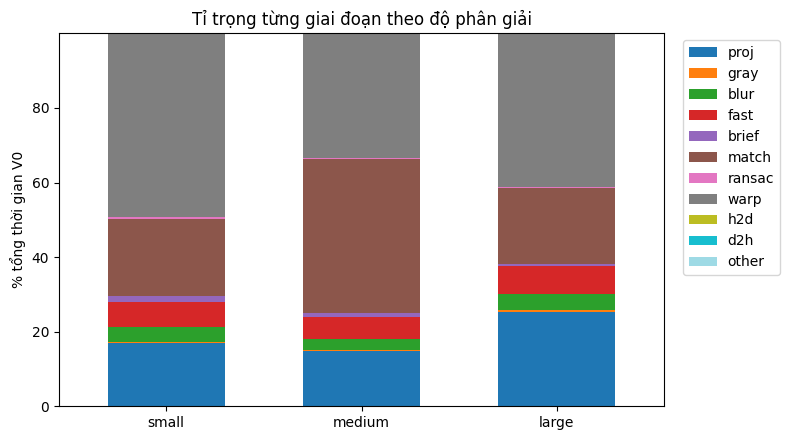

In [ ]:
t = tab.copy(); t.columns = list(SIZES)
pct = (t.loc[STAGES + ["other"]] / t.loc["total(e2e)"] * 100)
print("Tỉ trọng mỗi giai đoạn trong tổng thời gian (%):")
display(pct.round(1))

growth = (t[list(SIZES)].div(t["small"], axis=0)).loc[[s for s in STAGES if t.loc[s, "small"] > 0] + ["total(e2e)"]]
growth.loc["(số pixel)"] = [(w * h) / (1280 * 720) for w, h in SIZES.values()]
print("Hệ số tăng thời gian so với small:")
display(growth.round(2))

for s in SIZES:
    top = pct[s].drop("other").sort_values(ascending=False).head(3)
    print(f"{s:6s} - hot stages:", ", ".join(f"{k} {v:.1f}%" for k, v in top.items()))

ax = pct.T.plot.bar(stacked=True, figsize=(8, 4.5), colormap="tab20", width=0.6)
ax.set_ylabel("% tổng thời gian V0"); ax.set_xlabel(""); ax.set_title("Tỉ trọng từng giai đoạn theo độ phân giải")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.xticks(rotation=0); plt.tight_layout()

## Phần G – Ước lượng Amdahl

Nếu các giai đoạn dự định tăng tốc chiếm tỉ lệ `p` thời gian của V0 thì speedup end-to-end **không bao giờ vượt** `1 / (1 − p)`, dù phần GPU nhanh đến đâu.
Ví dụ: các giai đoạn đó chiếm 90% thời gian → tối đa 10×.

👉 Sửa `ACCEL` thành **đúng các giai đoạn nhóm dự định đưa lên GPU**. `p` tính trên `total(e2e)` của V0.

In [ ]:
ACCEL = ["gray", "blur", "fast", "brief", "match", "ransac", "warp"]     # SỬA theo kế hoạch của nhóm (có thể thêm "proj")

rows_a = []
for s in SIZES:
    p = t.loc[ACCEL, s].sum() / t.loc["total(e2e)", s]
    row = {"size": f"{s} ({SIZES[s][0]}x{SIZES[s][1]})", "V0 total (ms)": t.loc["total(e2e)", s],
           "accelerated (ms)": t.loc[ACCEL, s].sum(), "p": p,
           "limit 1/(1-p)": 1 / (1 - p) if p < 1 else float("inf")}
    for sp in (10, 50, 100):                                            # speedup nếu phần tăng tốc nhanh hơn sp lần
        row[f"speedup nếu GPU part x{sp}"] = 1 / ((1 - p) + p / sp)
    rows_a.append(row)

amdahl = pd.DataFrame(rows_a).set_index("size")
print("Các giai đoạn dự định tăng tốc:", ACCEL)
display(amdahl.round(3))
for s, r_ in amdahl.iterrows():
    print(f"{s:20s} p = {r_['p']:.3f}  ->  speedup tối đa = {r_['limit 1/(1-p)']:.2f}x")

Các giai đoạn dự định tăng tốc: ['gray', 'blur', 'fast', 'brief', 'match', 'ransac', 'warp']


,V0 total (ms),accelerated (ms),p,limit 1/(1-p),speedup nếu GPU part x10,speedup nếu GPU part x50,speedup nếu GPU part x100
size,,,,,,,
small (1280x720),1206.244,1002.839,0.831,5.930,3.972,5.398,5.652
medium (1920x1080),2456.415,2095.422,0.853,6.805,4.305,6.097,6.431
large (3840x2160),7677.512,5727.653,0.746,3.937,3.043,3.719,3.825


small (1280x720)     p = 0.831  ->  speedup tối đa = 5.93x
medium (1920x1080)   p = 0.853  ->  speedup tối đa = 6.80x
large (3840x2160)    p = 0.746  ->  speedup tối đa = 3.94x
